# Лабораторная работа №4 — байесовская сеть

**Данные:** [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality), красное и белое вино. Один объект — образец вина с измерениями состава и экспертной оценкой качества. Используются файлы из соседней папки regression.

**Задача:** построить небольшую сеть, оценить условные вероятности и посмотреть, как сведения о вине меняют вероятность высокой оценки. Стрелки графа задают модель зависимостей, а не доказанные причинные связи.


## 1. Данные и подготовка

Исходные файлы содержат тип вина (из имени файла), содержание алкоголя, летучую кислотность и экспертную оценку quality. Сначала проверяем пропуски, полные дубликаты и диапазоны значений. Полные дубликаты оставляем: в данных нет идентификатора образца, поэтому нельзя определить, являются ли совпадающие строки повторной записью или разными образцами с одинаковыми измерениями. Это ограничение оценки вероятностей.


In [1]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import FancyArrowPatch

data_dir = Path("..") / "regression"
red = pd.read_csv(data_dir / "winequality-red.csv", sep=";")
white = pd.read_csv(data_dir / "winequality-white.csv", sep=";")
red["Type"] = "red"
white["Type"] = "white"
raw = pd.concat([red, white], ignore_index=True)

print("Объектов:", len(raw), "(red:", len(red), ", white:", len(white), ")")
print("Пропусков:", int(raw.isna().sum().sum()))
print("Полных дубликатов:", int(raw.duplicated().sum()))
display(raw[["alcohol", "volatile acidity", "quality"]].describe().round(2))


Объектов: 6497 (red: 1599 , white: 4898 )
Пропусков: 0
Полных дубликатов: 1177


,alcohol,volatile acidity,quality
count,6497.00,6497.00,6497.00
mean,10.49,0.34,5.82
std,1.19,0.16,0.87
min,8.00,0.08,3.00
25%,9.50,0.23,5.00
50%,10.30,0.29,6.00
75%,11.30,0.40,6.00
max,14.90,1.58,9.00


Непрерывные величины переводим в два состояния, чтобы таблицы условных вероятностей оставались читаемыми:

| Переменная | Состояния | Правило |
|---|---|---|
| Type | red, white | Исходный файл |
| Alcohol | low, high | high при alcohol ≥ 10.5; порог близок к медиане 10.3 |
| Acidity | low, high | high при volatile acidity ≥ 0.35; порог немного выше медианы 0.29 |
| Quality | ordinary, high | high при quality ≥ 7; оценка 7 и выше составляет меньшую часть данных |

Пороги зафиксированы перед построением сети. Дискретизация упрощает модель, но теряет информацию о значениях внутри интервалов.


In [2]:
data = pd.DataFrame({
    "Type": raw["Type"],
    "Alcohol": np.where(raw["alcohol"] >= 10.5, "high", "low"),
    "Acidity": np.where(raw["volatile acidity"] >= 0.35, "high", "low"),
    "Quality": np.where(raw["quality"] >= 7, "high", "ordinary"),
})
states = {
    "Type": ("red", "white"),
    "Alcohol": ("low", "high"),
    "Acidity": ("low", "high"),
    "Quality": ("ordinary", "high"),
}
print("Частоты состояний:")
for variable in states:
    print(variable, data[variable].value_counts().reindex(states[variable]).to_dict())

parent_counts = data.groupby(["Type", "Alcohol", "Acidity"]).size()
high_counts = (
    data.loc[data["Quality"] == "high"]
    .groupby(["Type", "Alcohol", "Acidity"]).size()
    .reindex(parent_counts.index, fill_value=0)
)
print("Комбинаций родителей Quality:", len(parent_counts),
      "; минимум объектов:", int(parent_counts.min()),
      "; минимум high:", int(high_counts.min()))
display(pd.DataFrame({"n": parent_counts, "high": high_counts}))


Частоты состояний:
Type {'red': 1599, 'white': 4898}
Alcohol {'low': 3491, 'high': 3006}
Acidity {'low': 4236, 'high': 2261}
Quality {'ordinary': 5220, 'high': 1277}
Комбинаций родителей Quality: 8 ; минимум объектов: 92 ; минимум high: 5


n  high
Type  Alcohol Acidity            
red   high    high      525   108
              low       158    80
      low     high      824    18
              low        92    11
white high    high      448   187
              low      1875   651
      low     high      464     5
              low      2111   217

## 2. Вопросы до построения графа

1. Как изменится вероятность высокой оценки, если содержание алкоголя высокое?
2. Как изменится вероятность высокой оценки, если летучая кислотность низкая?
3. При высоком алкоголе и низкой кислотности добавление информации «вино красное» повышает или понижает вероятность высокой оценки?


## 3. Структура сети

Предлагаем ориентированный ациклический граф: Type → Alcohol, Type → Acidity, Type → Quality, Alcohol → Quality, Acidity → Quality.

- Направление Type → Alcohol и Type → Acidity отражает гипотезу, что различия сырья и технологии красного и белого вина связаны с их измеряемым составом. Оно не следует только из корреляции.
- Alcohol → Quality и Acidity → Quality отражают гипотезу, что химический состав может быть связан с последующей экспертной оценкой вкуса.
- Type → Quality оставляет возможность различий в оценке красного и белого вина, которые два выбранных измерения не объясняют.

Другие признаки не добавляем, чтобы сохранить проверяемые таблицы вероятностей и понятный граф. Порядок стрелок является предположением, а не выводом о причинности из этих наблюдений.


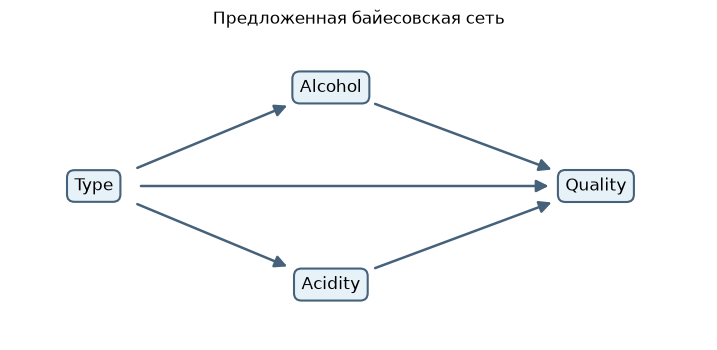

In [3]:
order = ("Type", "Alcohol", "Acidity", "Quality")
parents = {
    "Type": (),
    "Alcohol": ("Type",),
    "Acidity": ("Type",),
    "Quality": ("Type", "Alcohol", "Acidity"),
}
assert all(order.index(parent) < order.index(child)
           for child in order for parent in parents[child])

positions = {
    "Type": (0.12, 0.50),
    "Alcohol": (0.46, 0.82),
    "Acidity": (0.46, 0.18),
    "Quality": (0.84, 0.50),
}
fig, ax = plt.subplots(figsize=(9, 4))
for child in order:
    for parent in parents[child]:
        arrow = FancyArrowPatch(
            positions[parent], positions[child],
            arrowstyle="-|>", mutation_scale=18, linewidth=1.8,
            color="#45627a", shrinkA=34, shrinkB=34,
        )
        ax.add_patch(arrow)
for node, (x, y) in positions.items():
    ax.text(x, y, node, ha="center", va="center", fontsize=12,
            bbox=dict(boxstyle="round,pad=0.45", facecolor="#e7f1f8",
                      edgecolor="#45627a", linewidth=1.5))
ax.set(xlim=(0, 1), ylim=(0, 1), title="Предложенная байесовская сеть")
ax.axis("off")
plt.show()


## 4. Условные вероятности

Оцениваем каждую таблицу по частотам с добавлением 1 к числу наблюдений каждого состояния (сглаживание Лапласа):

$\hat P(X=x\mid Pa(X)=u)=(N(x,u)+1)/(N(u)+|X|)$.

Это особенно полезно там, где высокая оценка встречается редко. Ниже сравниваем вероятности сети с наблюдаемыми долями.


In [4]:
def fit_cpts(frame, parent_map, alpha=1):
    result = {}
    for node in order:
        result[node] = {}
        combos = list(product(*(states[p] for p in parent_map[node])))
        if not combos:
            combos = [()]
        for combo in combos:
            subset = frame
            for parent, value in zip(parent_map[node], combo):
                subset = subset.loc[subset[parent] == value]
            counts = subset[node].value_counts().reindex(states[node], fill_value=0)
            probabilities = (counts + alpha) / (counts.sum() + alpha * len(states[node]))
            result[node][combo] = probabilities.to_dict()
    return result

cpts = fit_cpts(data, parents)
for node in ("Type", "Alcohol", "Acidity"):
    rows = []
    for combo, probabilities in cpts[node].items():
        row = dict(zip(parents[node], combo))
        row.update({f"P({state})": probability
                    for state, probability in probabilities.items()})
        rows.append(row)
    print("Таблица для", node)
    display(pd.DataFrame(rows).round(3))

quality_rows = []
for combo, probabilities in cpts["Quality"].items():
    selection = data
    for parent, value in zip(parents["Quality"], combo):
        selection = selection.loc[selection[parent] == value]
    quality_rows.append({
        "Type": combo[0], "Alcohol": combo[1], "Acidity": combo[2],
        "n": len(selection),
        "P(high) сеть": probabilities["high"],
        "Доля high в данных": (selection["Quality"] == "high").mean(),
    })
quality_table = pd.DataFrame(quality_rows)
print("Таблица для Quality и сверка с исходными долями:")
display(quality_table.round(3))
print("Максимальное расхождение из-за сглаживания:",
      round((quality_table["P(high) сеть"] -
             quality_table["Доля high в данных"]).abs().max(), 4))


Таблица для Type


,P(red),P(white)
0,0.246,0.754


Таблица для Alcohol


,Type,P(low),P(high)
0,red,0.573,0.427
1,white,0.526,0.474


Таблица для Acidity


,Type,P(low),P(high)
0,red,0.157,0.843
1,white,0.814,0.186


Таблица для Quality и сверка с исходными долями:


,Type,Alcohol,Acidity,n,P(high) сеть,Доля high в данных
0,red,low,low,92,0.128,0.120
1,red,low,high,824,0.023,0.022
2,red,high,low,158,0.506,0.506
3,red,high,high,525,0.207,0.206
4,white,low,low,2111,0.103,0.103
5,white,low,high,464,0.013,0.011
6,white,high,low,1875,0.347,0.347
7,white,high,high,448,0.418,0.417


Максимальное расхождение из-за сглаживания: 0.0081


Самое маленькое сочетание родителей Quality содержит 92 наблюдения, но в одном из сочетаний высоких оценок всего 5. Поэтому редкие условные исходы следует трактовать осторожно. Максимальная разница между сглаженной вероятностью сети и наблюдаемой долей — 0,0081. Необычный результат: среди белых вин с высоким алкоголем доля высоких оценок при высокой кислотности составляет 41,7%, а при низкой — 34,7%. Это может отражать совместное влияние неучтённых признаков; из этих наблюдений нельзя заключить, что увеличение кислотности улучшит вино.

## 5. Вероятностные запросы

Точный вывод выполняем суммированием совместной вероятности по всем состояниям, которые не заданы как evidence. Совместная вероятность факторизуется по предложенному графу.


In [5]:
def joint_probability(assignment, tables, parent_map):
    probability = 1.0
    for node in order:
        parent_values = tuple(assignment[p] for p in parent_map[node])
        probability *= tables[node][parent_values][assignment[node]]
    return probability


def query(target, evidence, tables, parent_map):
    totals = {state: 0.0 for state in states[target]}
    for values in product(*(states[node] for node in order)):
        assignment = dict(zip(order, values))
        if all(assignment[node] == value for node, value in evidence.items()):
            totals[assignment[target]] += joint_probability(
                assignment, tables, parent_map
            )
    denominator = sum(totals.values())
    return {state: value / denominator for state, value in totals.items()}


total_joint = sum(
    joint_probability(dict(zip(order, values)), cpts, parents)
    for values in product(*(states[node] for node in order))
)
assert np.isclose(total_joint, 1.0)

questions = [
    ("1. Высокий алкоголь", {}, {"Alcohol": "high"}),
    ("2. Низкая кислотность", {}, {"Acidity": "low"}),
    ("3. Известен также тип red",
     {"Alcohol": "high", "Acidity": "low"},
     {"Alcohol": "high", "Acidity": "low", "Type": "red"}),
]
query_rows = []
for label, before, after in questions:
    p_before = query("Quality", before, cpts, parents)["high"]
    p_after = query("Quality", after, cpts, parents)["high"]
    query_rows.append({
        "Вопрос": label, "До": p_before, "После": p_after,
        "Изменение, п.п.": 100 * (p_after - p_before),
    })
display(pd.DataFrame(query_rows).round(3))


,Вопрос,До,После,"Изменение, п.п."
0,1. Высокий алкоголь,0.195,0.336,14.088
1,2. Низкая кислотность,0.195,0.223,2.781
2,3. Известен также тип red,0.356,0.506,15.036


**Ответы на вопросы.** По сети вероятность высокой оценки до дополнительных сведений составляет 19,5%. При высоком алкоголе она возрастает до 33,6% (+14,1 п.п.). При низкой кислотности — до 22,3% (+2,8 п.п.). Если уже известны высокий алкоголь и низкая кислотность, вероятность равна 35,6%; дополнительная информация, что вино красное, повышает её до 50,6% (+15,0 п.п.). Это условные связи в выбранной сети, а не эффекты вмешательства.

## 6. Последовательное добавление evidence

Для одной переменной Quality сравниваем распределение без сведений, при высоком алкоголе, затем при дополнительно низкой кислотности и, наконец, при известном красном типе вина.

,Evidence,P(ordinary),P(high)
0,Ничего не известно,0.805,0.195
1,Alcohol = high,0.664,0.336
2,+ Acidity = low,0.644,0.356
3,+ Type = red,0.494,0.506


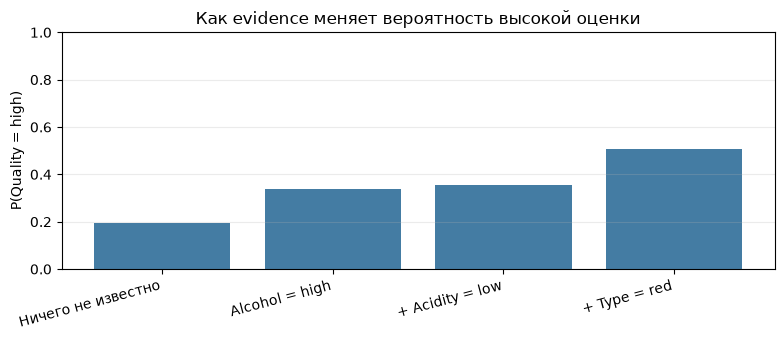

In [9]:
evidence_steps = [
    ("Ничего не известно", {}),
    ("Alcohol = high", {"Alcohol": "high"}),
    ("+ Acidity = low", {"Alcohol": "high", "Acidity": "low"}),
    ("+ Type = red", {"Alcohol": "high", "Acidity": "low", "Type": "red"}),
]
evidence_rows = []
for label, evidence in evidence_steps:
    probabilities = query("Quality", evidence, cpts, parents)
    evidence_rows.append({
        "Evidence": label,
        "P(ordinary)": probabilities["ordinary"],
        "P(high)": probabilities["high"],
    })
evidence_table = pd.DataFrame(evidence_rows)
display(evidence_table.round(3))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(evidence_table["Evidence"], evidence_table["P(high)"], color="#447ca3")
ax.set(ylabel="P(Quality = high)", ylim=(0, 1),
       title="Как evidence меняет вероятность высокой оценки")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


При последовательном добавлении evidence вероятность высокой оценки меняется с 19,5% на 33,6%, затем на 35,6% и 50,6%. Alcohol и Acidity — непосредственные родители Quality, поэтому сведения об их состояниях меняют её условную вероятность. Type тоже является родителем Quality; в модели красный тип даёт дополнительную информацию даже при известных значениях алкоголя и кислотности. Последняя группа содержит 158 наблюдений.

## 7. Удаление ребра

Удаляем Type → Quality, оставляя остальные рёбра. Заново оцениваем таблицу Quality уже по двум родителям — Alcohol и Acidity. Повторяем третий запрос. После удаления ребра Type не должен давать дополнительной информации о Quality, если Alcohol и Acidity уже известны.


In [7]:
parents_without_edge = {
    **parents,
    "Quality": ("Alcohol", "Acidity"),
}
cpts_without_edge = fit_cpts(data, parents_without_edge)
full_evidence = {"Alcohol": "high", "Acidity": "low", "Type": "red"}
original_result = query("Quality", full_evidence, cpts, parents)["high"]
changed_result = query(
    "Quality", full_evidence, cpts_without_edge, parents_without_edge
)["high"]
without_type = query(
    "Quality", {"Alcohol": "high", "Acidity": "low"},
    cpts_without_edge, parents_without_edge
)["high"]
display(pd.DataFrame([
    {"Структура": "Исходная", "P(Quality = high)": original_result},
    {"Структура": "Без Type → Quality", "P(Quality = high)": changed_result},
]).round(3))
print("После удаления ребра без сведения о Type:", round(without_type, 3))
assert np.isclose(changed_result, without_type)


,Структура,P(Quality = high)
0,Исходная,0.506
1,Без Type → Quality,0.360


После удаления ребра без сведения о Type: 0.36


## 8. Причинность и итог

Сеть **не является доказанной причинной моделью**. Направления стрелок опираются на понятную последовательность «тип и состав вина — экспертная оценка», но наблюдательные данные не исключают скрытые факторы и не позволяют уверенно выбрать направление всех связей. Для причинного вывода понадобились бы дополнительные предположения или экспериментальные данные.

Сеть показала сильную условную связь высокой оценки с высоким алкоголем и более слабую — с низкой летучей кислотностью. При известных высоком алкоголе и низкой кислотности указание красного типа повысило вероятность высокой оценки с 35,6% до 50,6%. Удаление ребра Type → Quality снизило ответ на тот же запрос до 36,0%: изменились факторизация и условные независимости графа. В изменённой сети Type уже не даёт новой информации о Quality после фиксации Alcohol и Acidity.

Ограничения: выбранные пороги теряют часть информации; сеть предполагает независимость Alcohol и Acidity при известном Type, хотя данные могут её нарушать; в одной условной группе только 5 высоких оценок; совпадающие строки могут переоценивать частоты; экспертная оценка субъективна. Поэтому значения вероятностей и вывод о роли Type зависят от структуры и состава данных.